# Kalp Hastalığı Tahmini: Adım Adım Sınıflandırma

Bu çalışmada hastaların yaş, kan basıncı, EKG ölçümleri gibi 11 özelliğinden
yola çıkarak kalp hastalığı olup olmadığını tahmin ediyorum. Amacım sadece yüksek
doğruluk almak değil; veriyi anlamak, hataların türünü incelemek ve modelin
neye bakarak karar verdiğini yorumlamak.

**Veri seti:** Heart Failure Prediction Dataset (918 satır, 11 özellik)
**Problem türü:** İkili sınıflandırma (0: sağlıklı, 1: hasta)

In [1]:
import numpy as np 
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub


/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv")
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()
df.describe()
df["HeartDisease"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


HeartDisease
1    508
0    410
Name: count, dtype: int64

## 1. Veriye İlk Bakış
Bu çıktıdan öğrendiklerimize bakarsak 918 satır ve 12 sütunumuz var.Görünürde eksik verimiz yok non-null yazısından bunu anlıyoruz.Ama bu kesin değil ileriki zamanlarda daha detaylı kontrol edeceğiz.object veri tipleri var fakat modeller metinle calışmaz bu yüzden onları ileride sayılara çevireceğiz.508 hasta ve 410 sağlıklı var oran dengeli sayılır bu sebeple de doğruluk metriği anlamlı olur.

In [4]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


## 2. Veri Kalitesi: Gizli Eksik Değerler
Bu çıktıda sahte verileri yakalamak için describe kullandık.Sütunların min değerlerine bakınca cholesterol ve RestingBP nin 0 olması dikkat çekiyor.Dinlenme kan basıncı ya da kolesterol gerçek bir insanda 0 olabilir mi bunu düşünüp bu sütunları düzetmeye çalışıyoruz.

In [5]:
print((df["Cholesterol"] == 0).sum())
print((df["RestingBP"] == 0).sum())

172
1


172 satırda kolesterol,1 satırda da kan basıncı 0 çıkmış.Bu durumda kolesterol değerlerini önce NaN yapıp sonra bir değerle dolduracağız.Kan basıncında sadece 1 satır olduğu için silmek en zararsız çözüm olur.Kolesterol u silmek büyük bir veri kaybına yol açagı ıcın onu silmiyoruz.

In [6]:
print(df[df["Cholesterol"] == 0]["HeartDisease"].value_counts())

HeartDisease
1    152
0     20
Name: count, dtype: int64


Kolesterol u 0 çıkan yani eksik olan 172 satırın 152 si hasta.Bu sonuçlardan da silmenin yanlış olduğunu görüyoruz.

**Burada aslında eksikliğin kendisi bir ipucudur.Modelimiz kolesterol eksik bilgisinden hasta olma olasılığını öğrenebilir fakat bu tıbbi bir gerçek değil büyük ihtimalle verinin nasıl toplandığıyla ilgili bir iz.Anladığım kadarıyla bu veri seti birkaç farklı hastanenin verisinin birleştirilmesiyle oluşturulmuş ve bazı kaynaklarda kolesterol hiç ölçülmemiş.Yani model gerçek tıbbi örüntü yerine veri toplama alışkanlığını öğrenebilir.Bu tür şeye veri artefaktı diyoruz.**

In [7]:
#RestingBP=0 olan tek satırı sil
df = df[df["RestingBP"] != 0].copy()

#Cholesterol'deki 0'ları gerçek eksik değer (NaN) yap
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)

print(df.shape)
print(df.isna().sum())

(917, 12)
Age                 0
Sex                 0
ChestPainType       0
RestingBP           0
Cholesterol       171
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
dtype: int64


In [8]:
print(df.groupby(df["Cholesterol"].isna())["HeartDisease"].agg(["count", "mean"]))

             count      mean
Cholesterol                 
False          746  0.477212
True           171  0.883041


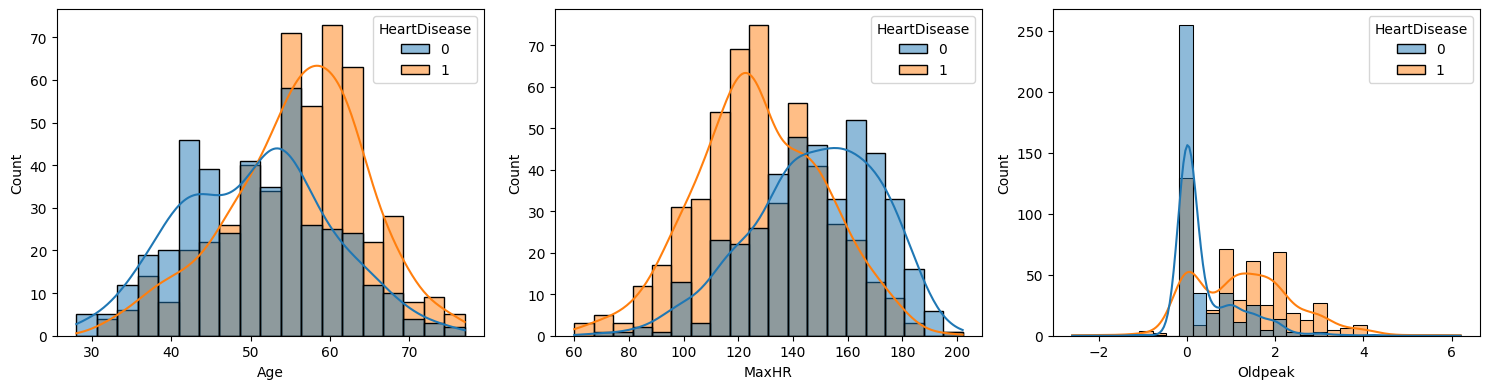

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=df, x="Age", hue="HeartDisease", kde=True, ax=axes[0])
sns.histplot(data=df, x="MaxHR", hue="HeartDisease", kde=True, ax=axes[1])
sns.histplot(data=df, x="Oldpeak", hue="HeartDisease", kde=True, ax=axes[2])
plt.tight_layout()
plt.show()

## 3. Keşifsel Veri Analizi
Hangi özelliğin hasta ve sağlıklıyı en iyi ayırdığına bakacağız bunun için tepeler ne kadar ayrıksa o kadar iyi ayırırız yani üst üste binmeler arttıkça ayırmak zorlasır.Age grafiğine bakınca iki dağılımın büyük bir kısmı üst üste binmiş yani ayrım orta düzeyde diyebiliriz.MaxHR ye bakınca burada ayrım daha belirgin iki tepe birbirinden net ayrılıyor yani bu özellik güçlü bir ayırıcı diyebiliriz.Son olarak oldpeak e bakarsak sağlıklıların çoğunun oldpeak değeri 0 veya 0'a çok yakın.Oldpeak yüksekse hasta olma ihtimali belirgin şekilde artıyor.Bu da güçlü bir ayırıcıdır.

**!**
Oldpeak grafiğinin solunda negatif değerler görünüyor.ST çökmesi normalde 0 ve üzeri olarak düşünülür,o yüzden bu birkaç satır şüpheli.Şimdilik dokunmayacağız.
Ayrıca grafikler tek özelliğe bakıyor. Model hepsini birlikte kullanacağı için, burada zayıf görünen bir özellik başkalarıyla birleşince işe yarayabilir.

In [10]:
cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

for col in cat_cols:
    print(df.groupby(col)["HeartDisease"].agg(["count", "mean"]).round(2))
    print()

     count  mean
Sex             
F      193  0.26
M      724  0.63

               count  mean
ChestPainType             
ASY              496  0.79
ATA              173  0.14
NAP              202  0.35
TA                46  0.43

            count  mean
RestingECG             
LVH           188  0.56
Normal        551  0.52
ST            178  0.66

                count  mean
ExerciseAngina             
N                 546  0.35
Y                 371  0.85

          count  mean
ST_Slope             
Down         63  0.78
Flat        459  0.83
Up          395  0.20



**Kategorik özellikler**
* ChestPainType	0.14 - 0.79	Çok güçlü
* ST_Slope	0.20 - 0.83	Çok güçlü
* ExerciseAngina	0.35 - 0.85	Güçlü
* Sex	0.26 - 0.63	Orta
* RestingECG	0.52 - 0.66	Zayıf

* **count** o kategoride kaç kişi var.
* **mean** o kategorideki hasta oranı.

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(733, 11) (184, 11)


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

preprocess = ColumnTransformer(
    [
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc", StandardScaler()),
        ]), num_cols),
        ("cat", OneHotEncoder(drop="first"), cat_cols),
    ],
    remainder="passthrough",
)

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])

model.fit(X_train, y_train)
print("Eğitim doğruluğu:", round(model.score(X_train, y_train), 3))
print("Test doğruluğu:  ", round(model.score(X_test, y_test), 3))

Eğitim doğruluğu: 0.859
Test doğruluğu:   0.886


In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    print(f"{name:20s} ort: {scores.mean():.3f}  (std: {scores.std():.3f})")

Logistic Regression  ort: 0.867  (std: 0.019)
KNN                  ort: 0.852  (std: 0.018)
Random Forest        ort: 0.864  (std: 0.023)


## 4. Model Karşılaştırması

Üç model de birbirine çok yakın farklar standart sapmanın altında kalıyor.
Tek bir train/test bölmesinde %88,6 almıştım, ama bunun şanslı bir bölme
olduğunu çapraz doğrulama gösterdi. Gerçek performans yaklaşık %86-87

Doğruluk eşit olduğu için daha basit ve yorumlanabilir olan
**Logistic Regression** ile devam ettim.

[[340  70]
 [ 52 455]]

              precision    recall  f1-score   support

    Sağlıklı       0.87      0.83      0.85       410
       Hasta       0.87      0.90      0.88       507

    accuracy                           0.87       917
   macro avg       0.87      0.86      0.86       917
weighted avg       0.87      0.87      0.87       917



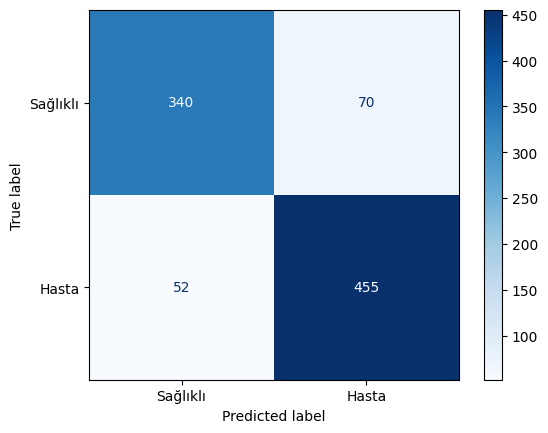

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

pipe = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])

y_pred = cross_val_predict(pipe, X, y, cv=cv)

print(confusion_matrix(y, y_pred))
print()
print(classification_report(y, y_pred, target_names=["Sağlıklı", "Hasta"]))

ConfusionMatrixDisplay.from_predictions(
    y, y_pred, display_labels=["Sağlıklı", "Hasta"], cmap="Blues"
)
plt.show()


## 5. Hata Analizi
* Bu tabloda satırlar gerçek durumu sütunlar ise modelin tahminini belirtir.
* 340 ve 455 doğru tahminler.
* 70 "yanlış pozitif" yani sağlıklı olduğu halde hasta denmiş.Zararı sınırlıdır.
* 52 "yanlış negatif" yani hasta olduğu halde sağlıklı denmiş.Tıpta en tehlikeli hatalardandır.


* Recall (yakalama oranı):Gerçek hastaların yüzde kaçını buldum?
* Hasta için 0.90
* Yani 100 gerçek hastanın 90'ını yakalıyoruz, 10'unu kaçırıyoruz.

* Precision (isabet oranı):Hasta dediklerimin yüzde kaçı gerçekten hasta?
* Hasta için 0.87
* Yani “hasta” dediğimiz 100 kişiden 87'si gerçekten hasta, 13'ü yanlış alarm.

In [15]:
from sklearn.metrics import recall_score, precision_score

proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:,1]

for esik in [0.3, 0.4, 0.5, 0.6]:
    tahmin = (proba >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, tahmin).ravel()
    print(
        f"Eşik {esik}: recall={recall_score(y, tahmin):.2f}  "
        f"precision={precision_score(y, tahmin):.2f}  "
        f"kaçırılan hasta (FN)={fn}  yanlış alarm (FP)={fp}"
    )

Eşik 0.3: recall=0.94  precision=0.82  kaçırılan hasta (FN)=30  yanlış alarm (FP)=108
Eşik 0.4: recall=0.92  precision=0.84  kaçırılan hasta (FN)=43  yanlış alarm (FP)=87
Eşik 0.5: recall=0.90  precision=0.87  kaçırılan hasta (FN)=52  yanlış alarm (FP)=70
Eşik 0.6: recall=0.85  precision=0.88  kaçırılan hasta (FN)=76  yanlış alarm (FP)=58


* Eşik düşünce model daha az kanıtla “hasta” der, yani daha çok kişiye “hasta” denir.
* Eşik 0'a çok yaklaşırsa neredeyse herkese “hasta” denir. Kaçırılan hasta 0 olur, ama 410 sağlıklının hepsi yanlış alarm olur.
* Eşik 1'e yaklaşırsa herkese “sağlıklı” denir. Yanlış alarm 0 olur, ama 507 hastanın hepsi kaçar.

In [16]:
pipe.fit(X, y)

isimler = pipe.named_steps["prep"].get_feature_names_out()
katsayilar = pipe.named_steps["clf"].coef_[0]

sonuc = pd.DataFrame({"ozellik": isimler, "katsayi": katsayilar})
sonuc = sonuc.reindex(sonuc["katsayi"].abs().sort_values(ascending=False).index)
print(sonuc.round(2).to_string(index=False))

               ozellik  katsayi
cat__ChestPainType_ATA    -1.69
            cat__Sex_M     1.47
cat__ChestPainType_NAP    -1.44
  remainder__FastingBS     1.24
    cat__ST_Slope_Flat     1.15
 cat__ChestPainType_TA    -1.14
      cat__ST_Slope_Up    -1.07
 cat__ExerciseAngina_Y     0.86
          num__Oldpeak     0.38
            num__MaxHR    -0.23
              num__Age     0.17
      num__Cholesterol     0.12
        num__RestingBP     0.03
    cat__RestingECG_ST     0.00
cat__RestingECG_Normal    -0.00


## 6. Model Neye Bakarak Karar Veriyor?

Katsayı işaretleri EDA bulgularımla uyumlu
- `ST_Slope_Up` ve `ChestPainType_ATA` negatif yani hasta olma ihtimalini düşürüyor.
- `Sex_M`, `ExerciseAngina_Y`, `Oldpeak` pozitif yani ihtimali artırıyor.
- `RestingECG` katsayıları sıfıra yakın, kategorik analizde de en zayıftı.


In [17]:
X2 = X.copy()
X2["Chol_missing"] = X2["Cholesterol"].isna().astype(int)

pipe_lr = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])

skor_A = cross_val_score(pipe_lr, X,  y, cv=cv) 
skor_B = cross_val_score(pipe_lr, X2, y, cv=cv)   

print(f"A: {skor_A.mean():.3f} (std {skor_A.std():.3f})")
print(f"B: {skor_B.mean():.3f} (std {skor_B.std():.3f})")

A: 0.867 (std 0.019)
B: 0.875 (std 0.018)


## 7. Deney: Eksik Kolesterol Bilgisi İşe Yarar mı?
Burada eksik kolesterolün hasta oranıyla bağlantılı olduğunu fark ettim, ek bir eksiklik göstergesi sütunuyla test ettim, ama çapraz doğrulamada anlamlı bir kazanç sağlamadığı için kullanmadım.

## 8. Sonuç ve Sınırlılıklar

**Sonuç:** Logistic Regression ile çapraz doğrulamada yaklaşık %87 doğruluk
ve hasta sınıfında %90-92 recall elde ettim. En belirleyici özellikler
göğüs ağrısı tipi, ST eğimi, egzersiz anjini ve cinsiyet.

**Sınırlılıklar:**
- Veri küçük (917 satır), skorlar +/-2 puan belirsizlik taşıyor.
- Örneklem erkek ağırlıklı; kadınlar için sonuçlar daha az güvenilir.
- Kolesterolün %19'u eksik ve eksiklik rastgele değil.
- Eşiği, sonuçlara bakarak aynı veri üzerinde seçtim; gerçek bir uygulamada
  ayrı bir doğrulama verisi gerekir.
- Model ilişkiyi gösterir, nedenselliği değil; tıbbi karar aracı değildir.